# Change in Crime Categories Over Time
### Research question 1: How has total crime in each crime category changed over the course of the years?
**Hypothesis:** Annual recorded crime counts show an increasing or decreasing trend over time in at least one crime category.

## 1. Imports

In [1]:
# Import required Library
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

## 2. Load dataset

In [2]:
df = pd.read_csv("dataset_coursework1-1.csv", low_memory=False)
print("Original headers:", df.columns.tolist())

# If the first row was actually data (no header), reload with header=None
if str(df.columns[0]).strip().isdigit():
    df = pd.read_csv("dataset_coursework1-1.csv", header=None, low_memory=False)

Original headers: ['Incident ID', 'Offence Code', 'CR Number', 'Dispatch Date / Time', 'Start_Date_Time', 'End_Date_Time', 'NIBRS Code', 'Victims', 'Crime Name1', 'Crime Name2', 'Crime Name3', 'Police District Name', 'Block Address', 'City', 'State', 'Zip Code', 'Agency', 'Place', 'Sector', 'Beat', 'PRA', 'Address Number', 'Street Prefix', 'Street Name', 'Street Suffix', 'Street Type', 'Latitude', 'Longitude', 'Police District Number', 'Location']


In [3]:
# Assign standard 30-column NIBRS names by position
canonical_cols = [
    "Incident ID", "Offense Code", "CR Number", "Dispatch Date/Time",
    "Start Date/Time", "End Date/Time", "NIBRS Code", "Victims",
    "Crime Name 1", "Crime Name 2", "Crime Name 3", "Police District Name",
    "Block Address", "City", "State", "Zip Code", "Agency", "Place",
    "Sector", "Beat", "PRA", "Address Number", "Street Prefix",
    "Street Name", "Street Suffix", "Street Type", "Latitude",
    "Longitude", "Police District Number", "Geolocation"
]

if df.shape[1] == 30:
    df.columns = canonical_cols
else:
    raise ValueError(f"Expected 30 columns, found {df.shape[1]}. Check separator/encoding.")

total_raw_rows = len(df)
print(f"Total raw rows: {total_raw_rows:,} | Columns: {df.shape[1]}")

Total raw rows: 508,106 | Columns: 30


## 3. Data quality checks

In [4]:
# Ensure numeric types for Latitude/Longitude/Victims
for num_col in ["Latitude", "Longitude", "Victims"]:
    df[num_col] = pd.to_numeric(df[num_col], errors="coerce")

# Date Parsing & Temporal Consistency Check
date_cols = ["Dispatch Date/Time", "Start Date/Time", "End Date/Time"]
for col in date_cols:
    df[col] = pd.to_datetime(df[col], format="%m/%d/%Y %I:%M:%S %p", errors="coerce")

invalid_end = (df["End Date/Time"] < df["Start Date/Time"]).sum()
out_of_scope = ((df["Start Date/Time"] < "2016-07-01") | (df["Start Date/Time"] > "2026-09-10 23:59:59")).sum()
print(f"End Date < Start Date anomalies: {invalid_end:,} ({invalid_end/total_raw_rows*100:.2f}%)")
print(f"Out-of-scope timestamps:        {out_of_scope:,} ({out_of_scope/total_raw_rows*100:.2f}%)")

End Date < Start Date anomalies: 8,418 (1.66%)
Out-of-scope timestamps:        228 (0.04%)


## 4. Cleaning, transformation & feature engineering

In [5]:
df_clean = df.copy()

df_clean["Crime Name 1"] = df_clean["Crime Name 1"].fillna("Unknown / Unclassified")
df_clean["Police District Name"] = df_clean["Police District Name"].astype(str).str.strip().str.upper().replace("NAN", "UNKNOWN")
df_clean["City"] = df_clean["City"].astype(str).str.strip().str.upper().replace("NAN", "UNKNOWN")

df_clean.loc[df_clean["End Date/Time"] < df_clean["Start Date/Time"], "End Date/Time"] = pd.NaT

exact_dups = df_clean.duplicated(subset=["Incident ID"], keep=False).sum()
print(f"Rows involved in duplicate Incident IDs: {exact_dups:,}")

df_clean = df_clean.drop_duplicates(subset=["Incident ID"])
print(f"Cleaned rows: {len(df_clean):,}")

# Feature Engineering
df_clean["Year"] = df_clean["Start Date/Time"].dt.year

Rows involved in duplicate Incident IDs: 74,254
Cleaned rows: 467,601


## 5. Crime categories overview

In [6]:
level1 = df_clean.groupby("Crime Name 1").size().reset_index(name="Count").sort_values("Count", ascending=False)
level2 = df_clean.groupby(["Crime Name 1", "Crime Name 2"]).size().reset_index(name="Count").sort_values(["Crime Name 1", "Count"], ascending=[True, False])

display(level1)
display(level2)

,Crime Name 1,Count
2,Crime Against Property,228483
3,Crime Against Society,185456
1,Crime Against Person,47583
0,Crime Against Not a Crime,6079


,Crime Name 1,Crime Name 2,Count
1,Crime Against Not a Crime,Runaway,6064
0,Crime Against Not a Crime,Justifiable Homicide,15
12,Crime Against Person,Simple Assault,33467
2,Crime Against Person,Aggravated Assault,6789
4,Crime Against Person,Forcible Rape,3341
3,Crime Against Person,Forcible Fondling,2871
8,Crime Against Person,Intimidation,621
10,Crime Against Person,Murder and Nonnegligent Manslaughter,189
13,Crime Against Person,Statuory Rape,146
9,Crime Against Person,Kidnapping/Abduction,86


## 6. Crime counts per year by category

In [7]:
yearly = df_clean[(df_clean["Start Date/Time"] >= "2016-07-01") &
                  (df_clean["Start Date/Time"] <= "2026-09-10 23:59:59")]
# Year x Crime Category counts
crime_by_year = pd.crosstab(yearly["Year"], yearly["Crime Name 1"])
crime_by_year["Total"] = crime_by_year.sum(axis=1)
crime_by_year["Total_YoY_%"] = crime_by_year["Total"].pct_change().mul(100).round(1)

display(crime_by_year)

Crime Name 1,Crime Against Not a Crime,Crime Against Person,Crime Against Property,Crime Against Society,Total,Total_YoY_%
Year,,,,,,
2016,335,2194,11648,11737,25914,NaN
2017,679,4425,22953,23738,51795,99.9
2018,624,4506,20403,24300,49833,-3.8
2019,634,4343,21119,22255,48351,-3.0
2020,499,3903,21180,15812,41394,-14.4
2021,429,4523,21430,15144,41526,0.3
2022,608,4905,22746,16740,44999,8.4
2023,481,5294,25893,11769,43437,-3.5
2024,557,5277,25102,15293,46229,6.4


In [8]:
crime_long = (
    yearly.groupby(["Year", "Crime Name 1"])
    .size()
    .reset_index(name="Count")
    .sort_values(["Year", "Count"], ascending=[True, False])
)
display(crime_long)

,Year,Crime Name 1,Count
3,2016,Crime Against Society,11737
2,2016,Crime Against Property,11648
1,2016,Crime Against Person,2194
0,2016,Crime Against Not a Crime,335
7,2017,Crime Against Society,23738
6,2017,Crime Against Property,22953
5,2017,Crime Against Person,4425
4,2017,Crime Against Not a Crime,679
11,2018,Crime Against Society,24300
10,2018,Crime Against Property,20403


## 7. Figure 1. Crime incidents per year by crime category

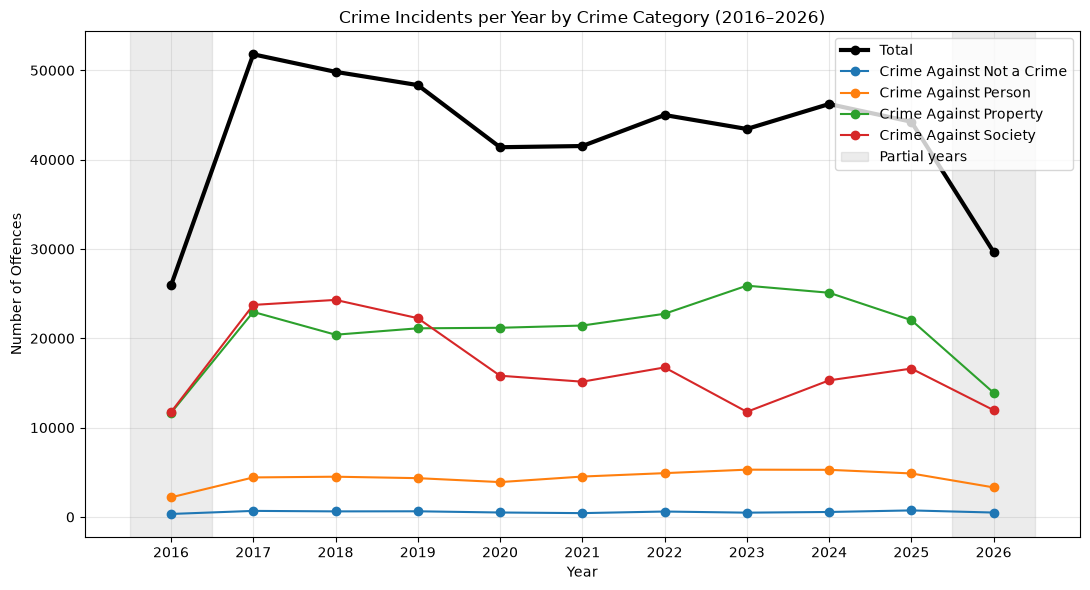

In [9]:
categories = [c for c in crime_by_year.columns if c not in ["Total", "Total_YoY_%"]]

fig, ax = plt.subplots(figsize=(11, 6))
ax.plot(crime_by_year.index, crime_by_year["Total"], marker="o", linewidth=3, color="black", label="Total")
for cat in categories:
    ax.plot(crime_by_year.index, crime_by_year[cat], marker="o", label=cat)

ax.axvspan(2025.5, 2026.5, color="grey", alpha=0.15, label="Partial years")
ax.axvspan(2015.5, 2016.5, color="grey", alpha=0.15)
ax.set_title("Crime Incidents per Year by Crime Category (2016–2026)")
ax.set_xlabel("Year")
ax.set_ylabel("Number of Offences")
ax.set_xticks(crime_by_year.index)
ax.legend()
ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

## 8. Figure 2. Share of crime categories per year (%)

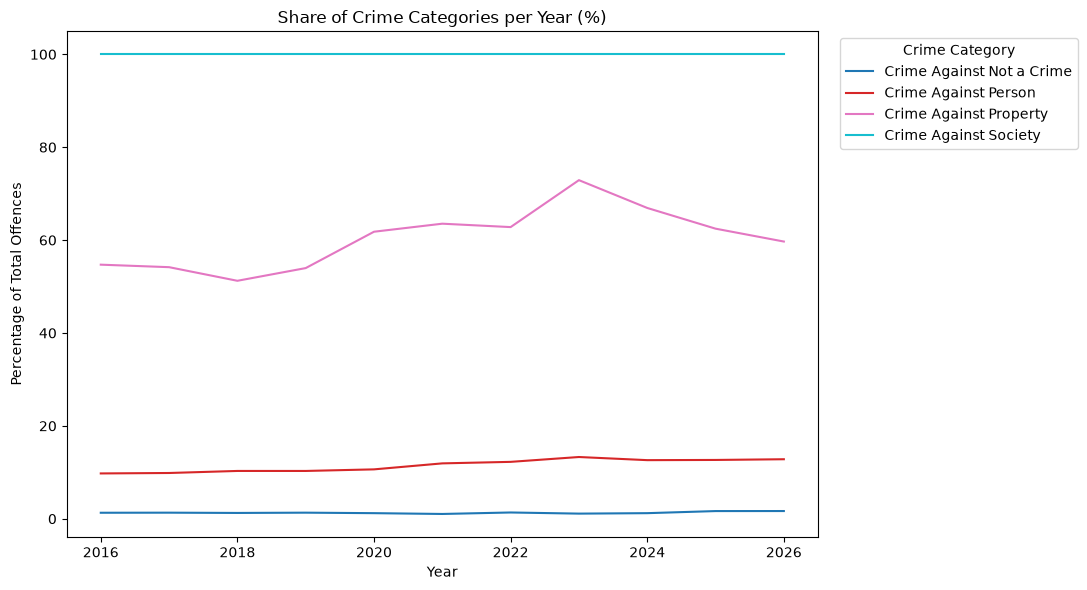

In [10]:
crime_share = crime_by_year[categories].div(crime_by_year["Total"], axis=0).mul(100)

crime_share.plot(kind="line", stacked=True, figsize=(11, 6), colormap="tab10")
plt.title("Share of Crime Categories per Year (%)")
plt.xlabel("Year")
plt.ylabel("Percentage of Total Offences")
plt.legend(title="Crime Category", bbox_to_anchor=(1.02, 1), loc="upper left")
plt.tight_layout()
plt.show()

## 9. Hypothesis check: linear trend per category (complete years 2017–2025)
A straight line is fitted to each category's annual counts. The slope shows the average change in offences per year, and R² shows how consistently the counts follow that line (closer to 1 = clearer trend). Partial years 2016 and 2026 are excluded so they don't distort the trend.

In [11]:
full_years = crime_by_year.loc[2017:2025, categories + ["Total"]]

rows = []
for cat in full_years.columns:
    x, y = full_years.index.values, full_years[cat].values
    slope, intercept = np.polyfit(x, y, 1)
    r2 = np.corrcoef(x, y)[0, 1] ** 2
    rows.append({
        "Crime Category": cat,
        "2017": y[0],
        "2025": y[-1],
        "Change_%": round((y[-1] - y[0]) / y[0] * 100, 1),
        "Slope (offences/year)": round(slope, 1),
        "R²": round(r2, 2),
        "Trend": "Increasing" if slope > 0 else "Decreasing",
    })

trend_summary = pd.DataFrame(rows).set_index("Crime Category")
display(trend_summary)

,2017,2025,Change_%,Slope (offences/year),R²,Trend
Crime Category,,,,,,
Crime Against Not a Crime,679,732,7.8,-3.1,0.01,Decreasing
Crime Against Person,4425,4871,10.1,116.7,0.49,Increasing
Crime Against Property,22953,22034,-4.0,358.9,0.28,Increasing
Crime Against Society,23738,16610,-30.0,-1259.6,0.62,Decreasing
Total,51795,44247,-14.6,-787.1,0.35,Decreasing
